# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name: Krishna Lund**
- **Roll No: 023-24-0271**
- **Section: H**
- **Date: 17-11-2026**

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b         

def step_function(z):
    return 1 if z >= 0 else 0        

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

# Slide 16
print("Slide 16:", predict([0.6, 0.8], [2, 3], -2))      

# Slide 17
w, b = [1, -0.5], 0.5
for x, exp in zip([[1, 1], [2, 1], [0, 3]], [1, 1, 0]):
    print(x, "z =", weighted_sum(w, x, b), "y_hat =", predict(w, x, b), "expected =", exp)

Slide 16: 1
[1, 1] z = 1.0 y_hat = 1 expected = 1
[2, 1] z = 2.0 y_hat = 1 expected = 1
[0, 3] z = -1.0 y_hat = 0 expected = 0


**Interpretation:**
predict returns 1 for slide 16, and gives 1, 1, 0 for the three slide-17 inputs (z = 1.0, 2.0, −1.0). All of these match the expected values, so the weighted sum, bias and step function are correct.

### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
w = np.array([0.2, -0.1]); b = 0.0; eta = 0.1; mistakes = 0

for xi, yi in zip(X_and, y_and):
    z = weighted_sum(w, xi, b)
    y_hat = step_function(z)
    e = yi - y_hat
    if e != 0:
        w = w + eta * e * xi
        b = b + eta * e
        mistakes += 1
    print(f"x={xi} y={yi} z={z:+.2f} y_hat={y_hat} e={e:+d} -> w={np.round(w,3)}, b={b:.2f}")

print("Final w:", np.round(w, 3), "b:", round(b, 2), "mistakes:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")

x=[0 0] y=0 z=+0.00 y_hat=1 e=-1 -> w=[ 0.2 -0.1], b=-0.10
x=[0 1] y=0 z=-0.20 y_hat=0 e=+0 -> w=[ 0.2 -0.1], b=-0.10
x=[1 0] y=0 z=+0.10 y_hat=1 e=-1 -> w=[ 0.1 -0.1], b=-0.20
x=[1 1] y=1 z=-0.20 y_hat=0 e=+1 -> w=[0.2 0. ], b=-0.10
Final w: [0.2 0. ] b: -0.1 mistakes: 3
Keep training.


**Interpretation:** The epoch ended with w = [0.2, 0.0], b = −0.1 and 3 mistakes: rows (0,0) and (1,0) were wrongly predicted 1 (weights lowered) and row (1,1) was wrongly predicted 0 (weights raised). Because mistakes > 0, it prints “Keep training”, so one epoch isn’t enough.

## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    w = np.zeros(X.shape[1]); b = 0.0
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, b)
            if e != 0:                   
                w = w + eta * e * xi
                b = b + eta * e
                errors += 1
        mistakes.append(errors)
        if errors == 0:                   
            break
    return w, b, mistakes

X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])
w_or, b_or, m_or = train_perceptron(X_or, y_or)
print("w =", np.round(w_or, 3), "b =", round(b_or, 3))    
print("Mistakes per epoch:", m_or)                          

w = [0.1 0.1] b = -0.1
Mistakes per epoch: [2, 2, 1, 0]


**Interpretation:** The perceptron learned OR with w = [0.1, 0.1] and b = −0.1, and the mistakes per epoch were [2, 2, 1, 0]. It updates only on mistakes and stops at the first zero-mistake epoch, which is epoch 4.

### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

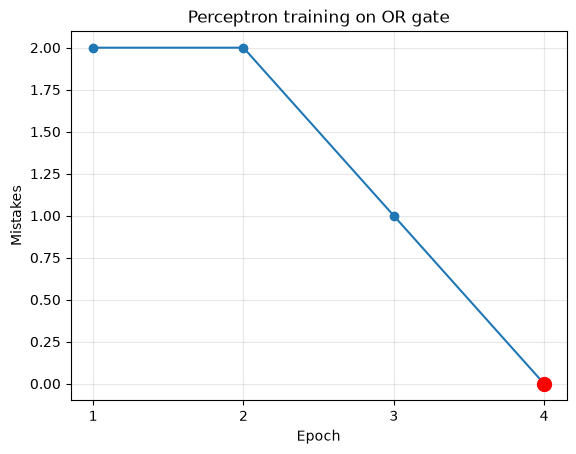

In [5]:
# Task 2.2
epochs = np.arange(1, len(m_or) + 1)
plt.plot(epochs, m_or, 'o-')
plt.plot(epochs[-1], m_or[-1], 'ro', markersize=10)
plt.xlabel("Epoch"); plt.ylabel("Mistakes")
plt.title("Perceptron training on OR gate")
plt.xticks(epochs); plt.grid(alpha=0.3); plt.show()

**Interpretation:** *Mistakes fall from 2 to 2 to 1 to 0, and the red dot marks zero mistakes at epoch 4. OR is linearly separable, so the convergence theorem guarantees training will stop.*

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

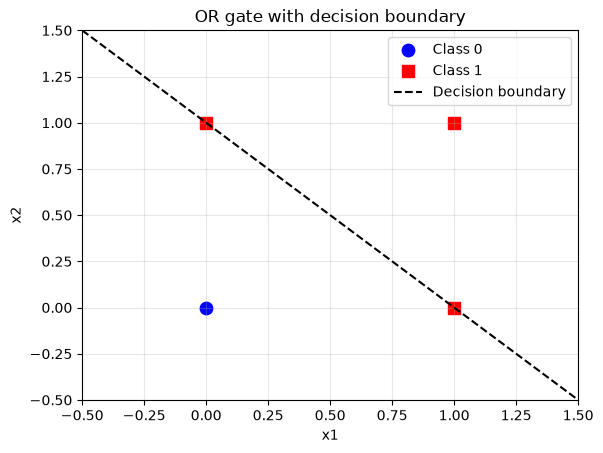

In [6]:
# Task 3.1
def plot_boundary(ax, w, b, xlim=(-0.5, 1.5), ylim=(-0.5, 1.5)):
    x1 = np.linspace(xlim[0], xlim[1], 100)
    if abs(w[1]) > 1e-12:                                 
        ax.plot(x1, -(w[0] / w[1]) * x1 - b / w[1], 'k--', label='Decision boundary')
    elif abs(w[0]) > 1e-12:                                
        ax.axvline(-b / w[0], color='k', linestyle='--', label='Decision boundary')
    ax.set_xlim(xlim); ax.set_ylim(ylim)

fig, ax = plt.subplots()
ax.scatter(X_or[y_or == 0, 0], X_or[y_or == 0, 1], c='blue', marker='o', s=80, label='Class 0')
ax.scatter(X_or[y_or == 1, 0], X_or[y_or == 1, 1], c='red',  marker='s', s=80, label='Class 1')
plot_boundary(ax, w_or, b_or)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("OR gate with decision boundary")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Interpretation:** *The dashed line is 0.1x₁ + 0.1x₂ − 0.1 = 0 (x₁ + x₂ = 1). It separates (0,0) from the other three points. ŷ = 1 on the side where w·x + b ≥ 0, which is the side the weight vector points toward (up and right).*

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias   : w = [0.1 0.1] b = -0.2 epochs = 4 final mistakes = 0
Without bias: w = [0.1 0. ] b = 0.0 epochs = 100 final mistakes = 2


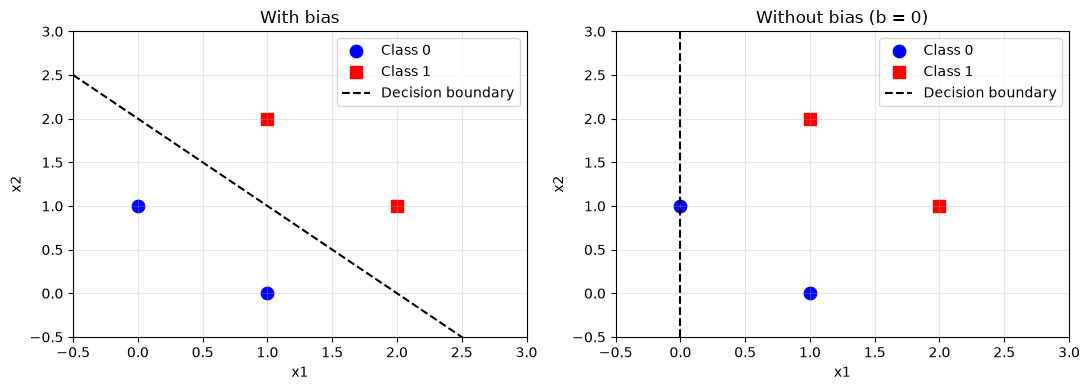

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    w = np.zeros(X.shape[1]); b = 0.0           
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, b)
            if e != 0:
                w = w + eta * e * xi            
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X3 = np.array([[1, 0], [0, 1], [2, 1], [1, 2]]); y3 = np.array([0, 0, 1, 1])
w_b,  b_b,  m_b  = train_perceptron(X3, y3)
w_nb, b_nb, m_nb = train_perceptron_nobias(X3, y3)
print("With bias   : w =", np.round(w_b, 3),  "b =", round(b_b, 2), "epochs =", len(m_b),  "final mistakes =", m_b[-1])
print("Without bias: w =", np.round(w_nb, 3), "b =", b_nb,          "epochs =", len(m_nb), "final mistakes =", m_nb[-1])

plt.figure(figsize=(11, 4))
for k, (w_, b_, t) in enumerate([(w_b, b_b, "With bias"), (w_nb, b_nb, "Without bias (b = 0)")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(X3[y3 == 0, 0], X3[y3 == 0, 1], c='blue', marker='o', s=80, label='Class 0')
    ax.scatter(X3[y3 == 1, 0], X3[y3 == 1, 1], c='red',  marker='s', s=80, label='Class 1')
    plot_boundary(ax, w_, b_, xlim=(-0.5, 3), ylim=(-0.5, 3))
    ax.set_title(t); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation:** *With bias, the perceptron converged in 4 epochs (w = [0.1, 0.1], b = −0.2) and its line sits between the two classes. Without bias, it did not converge: it used all 100 epochs and still made 2 mistakes. With b = 0 the boundary must pass through the origin (slide 19), and no line through the origin separates these points.*

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epochs run: 100 | Final mistakes: 4 | Best epoch: 3
w = [-0.1  0. ] b = 0.0


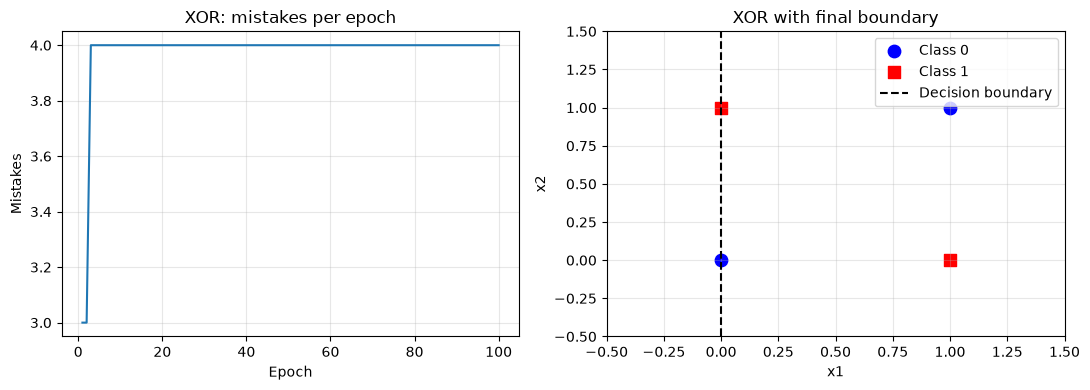

In [8]:
# Task 4.1
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); y_xor = np.array([0, 1, 1, 0])
w_x, b_x, m_x = train_perceptron(X_xor, y_xor, max_epochs=100)
print("Epochs run:", len(m_x), "| Final mistakes:", m_x[-1], "| Best epoch:", min(m_x))
print("w =", np.round(w_x, 3), "b =", round(b_x, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, len(m_x) + 1), m_x)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Mistakes"); axes[0].set_title("XOR: mistakes per epoch")
axes[0].grid(alpha=0.3)
axes[1].scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1], c='blue', marker='o', s=80, label='Class 0')
axes[1].scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], c='red',  marker='s', s=80, label='Class 1')
plot_boundary(axes[1], w_x, b_x)
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2"); axes[1].set_title("XOR with final boundary")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation:** *No, it never reaches zero mistakes. It ran all 100 epochs, the final epoch had 4 mistakes, and even the best epoch had 3. XOR is not linearly separable, since (0,1) and (1,0) lie on the opposite diagonal from (0,0) and (1,1), so no single straight line can separate them.*

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    return (np.dot(w, [0, 0]) + b <  0 and
            np.dot(w, [0, 1]) + b >= 0 and
            np.dot(w, [1, 0]) + b >= 0 and
            np.dot(w, [1, 1]) + b <  0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)
passing = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Passing triples:", len(passing), "out of 10000")
print("No solution found" if len(passing) == 0 else passing[0])

Passing triples: 0 out of 10000
No solution found


**Interpretation:** 0 of 10,000 random (w₁, w₂, b) triples satisfied all four XOR constraints, so it prints “No solution found”. This agrees with the algebraic proof in Q3. The random test is supporting evidence only, and the algebra is the actual proof.

## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X = iris.data[:, (2, 3)]
y = (iris.target == 0).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

clf = Perceptron(random_state=42).fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Rest", "Setosa"]))
print("coef_:", clf.coef_)
print("intercept_:", clf.intercept_)

Accuracy: 1.0
Confusion matrix:
 [[30  0]
 [ 0 15]]
              precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_: [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** *Accuracy is 1.0, and the confusion matrix [[30,0],[0,15]] has no errors, so precision, recall and F1 are all 1.0. Setosa is linearly separable from the other two species by petal size. coef_ = [−1.3, −2.2] is the weight vector w and intercept_ = 4.0 is the bias b from Part 1.*

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

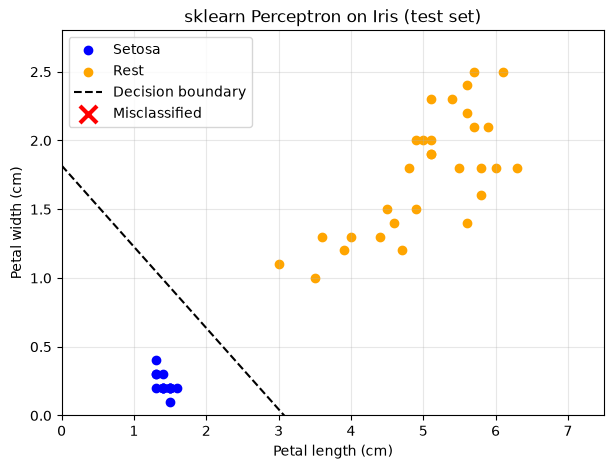

Misclassified: 0 of 45


In [11]:
# Task 5.2
w_sk, b_sk = clf.coef_[0], clf.intercept_[0]
wrong = y_pred != y_test

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c='blue',   label='Setosa')
ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c='orange', label='Rest')
plot_boundary(ax, w_sk, b_sk, xlim=(0, 7.5), ylim=(0, 2.8))
ax.scatter(X_test[wrong, 0], X_test[wrong, 1], c='red', marker='x', s=150, linewidths=3,
           label='Misclassified', zorder=5)          # plotted last
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.set_title("sklearn Perceptron on Iris (test set)"); ax.legend(); ax.grid(alpha=0.3); plt.show()
print("Misclassified:", wrong.sum(), "of", len(y_test))

**Interpretation:** *0 of 45 test points are misclassified, so no red × appears. The boundary is a straight line because it solves w₁x₁ + w₂x₂ + b = 0, which is linear. Both weights are negative, so Setosa (small petals) is on the side where ŷ = 1.*

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
print(f"{'eta0':>8} | {'accuracy':>8} | {'n_iter_':>7} | coef_")
models = []
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta0, random_state=42).fit(X_train, y_train)
    models.append(m)
    print(f"{eta0:>8} | {accuracy_score(y_test, m.predict(X_test)):>8.3f} | {m.n_iter_:>7} | {np.round(m.coef_[0], 4)}")

print("Same predictions for all three:", all((m.predict(X_test) == models[0].predict(X_test)).all() for m in models))

    eta0 | accuracy | n_iter_ | coef_
   0.001 |    1.000 |       6 | [-0.0013 -0.0022]
     0.1 |    1.000 |       7 | [-0.13 -0.22]
    10.0 |    1.000 |       7 | [-13. -22.]
Same predictions for all three: True


**Interpretation:** *Accuracy is 1.0 and predictions are identical for all three η values, because the coef_ vectors are the same vector scaled by η. Training starts from w = 0, so η only rescales the weights and bias and never changes the sign of w·x + b.*

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
Xa, ya = iris.data, iris.target
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.3, random_state=42, stratify=ya)

clf3 = Perceptron(random_state=42, max_iter=1000).fit(Xtr, ytr)
p3 = clf3.predict(Xte)

print(classification_report(yte, p3, target_names=iris.target_names, zero_division=0))
print("Confusion matrix:\n", confusion_matrix(yte, p3))
print("coef_.shape:", clf3.coef_.shape)

              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


**Interpretation:** *coef_.shape is (3, 4), so each row is one one-vs-rest perceptron with 4 feature weights, and overall accuracy is only 0.67. Versicolor is hardest (recall 0): 14 of its 15 flowers are predicted as setosa and 1 as virginica, because it sits between the other two classes and “versicolor vs rest” is not linearly separable.*

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
logreg = LogisticRegression(random_state=42, max_iter=200).fit(Xtr, ytr)
pl = logreg.predict(Xte)

print(f"{'Model':<22} | {'Accuracy':>8} | {'Macro-F1':>8}")
print(f"{'Perceptron':<22} | {accuracy_score(yte, p3):>8.4f} | {f1_score(yte, p3, average='macro'):>8.4f}")
print(f"{'Logistic Regression':<22} | {accuracy_score(yte, pl):>8.4f} | {f1_score(yte, pl, average='macro'):>8.4f}")

Model                  | Accuracy | Macro-F1
Perceptron             |   0.6667 |   0.5499
Logistic Regression    |   0.9333 |   0.9333


**Interpretation:** *Logistic regression is much better, with accuracy and macro-F1 both 0.9333 against 0.6667 and 0.5499 for the perceptron. The sigmoid is smooth and its gradient is never exactly zero, so it keeps improving the weights using how wrong each prediction is. The step function only says “right” or “wrong”, so on overlapping classes it keeps oscillating.*

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

- z = 0.5(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = 0.1
- ŷ = step(0.1) = 1, which is wrong because y = 0
- e = y − ŷ = 0 − 1 = −1
- w₁ = 0.5 + 0.1(−1)(1) = 0.4
- w₂ = −0.3 + 0.1(−1)(2) = −0.5
- b = 0.2 + 0.1(−1) = 0.1
- The prediction was too high, so the update lowered the weights and bias. w₂ moved twice as far as w₁ because x₂ = 2 is twice x₁ = 1.

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

- The boundary is where z = 0: 0.3x₁ + 0.2x₂ − 0.4 = 0
- Solving for x₂ gives x₂ = −1.5x₁ + 2
- At (1,1): z = 0.3 + 0.2 − 0.4 = 0.1 ≥ 0
- So (1,1) lies on the positive side of the line (the side w points toward), and ŷ = 1
- This matches AND(1,1) = 1. The other three inputs give z < 0 (−0.4, −0.2, −0.1), so ŷ = 0 for them.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**(a) Algebraic proof**

XOR requires all four constraints:

- (0,0) → 0: b < 0
- (0,1) → 1: w₂ + b ≥ 0
- (1,0) → 1: w₁ + b ≥ 0
- (1,1) → 0: w₁ + w₂ + b < 0

Add (2) and (3): w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ + b ≥ −b.
From (1), b < 0, so −b > 0. Therefore w₁ + w₂ + b > 0.
This contradicts (4), so no (w₁, w₂, b) satisfies all four constraints.

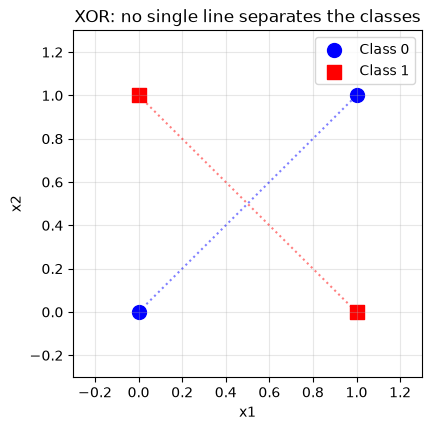

In [15]:
# (b) Sketch
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter([0, 1], [0, 1], c='blue', marker='o', s=100, label='Class 0')
ax.scatter([0, 1], [1, 0], c='red',  marker='s', s=100, label='Class 1')
ax.plot([0, 1], [0, 1], 'b:', alpha=0.5)
ax.plot([0, 1], [1, 0], 'r:', alpha=0.5)
ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.3, 1.3)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("XOR: no single line separates the classes")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**(b) Explanation**

Class 0 is at (0,0) and (1,1), and class 1 is at (0,1) and (1,0). Each class sits on its own diagonal, and the two diagonals cross in the middle. Any straight line that puts (0,1) and (1,0) on one side must also include a class-0 point, so no line separates the classes.

**(c) Architectural change**

Add a hidden layer, which makes a multi-layer perceptron (MLP). For example, 2 inputs feed 2 hidden neurons (one computing OR, one computing NAND), and an output neuron ANDs them: XOR = AND(OR, NAND).

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [16]:
# Q4
def run_iris(features):
    Xf = iris.data[:, features]
    ys = (iris.target == 0).astype(int)          
    a, b_, c, d = train_test_split(Xf, ys, test_size=0.3, random_state=42, stratify=ys)
    m = Perceptron(random_state=42).fit(a, c)
    p = m.predict(b_)
    return accuracy_score(d, p), f1_score(d, p, average='macro'), int((p != d).sum()), m.n_iter_

print(f"{'Features':<18} | {'Accuracy':>8} | {'Macro-F1':>8} | {'Errors':>6} | {'n_iter_':>7}")
for name, feats in [("(2, 3) petal", (2, 3)), ("(0, 2, 3) +sepal", (0, 2, 3))]:
    acc, f1, err, it = run_iris(feats)
    print(f"{name:<18} | {acc:>8.4f} | {f1:>8.4f} | {err:>6} | {it:>7}")

Features           | Accuracy | Macro-F1 | Errors | n_iter_
(2, 3) petal       |   1.0000 |   1.0000 |      0 |       7
(0, 2, 3) +sepal   |   1.0000 |   1.0000 |      0 |       7


*The extra feature does not help. Accuracy and macro-F1 are 1.0 with both feature sets, and training takes the same 7 iterations. Setosa vs rest is already perfectly linearly separable using petal length and width, so there is no error left for sepal length to remove. An extra feature only helps when the existing ones leave classes mixed.*

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Model       | Accuracy | Epochs | w, b
Hand-built  |   0.8167 |    100 | [ 0.307 -0.256], 0.200
sklearn     |   0.6667 |      6 | [2.281 0.58 ], 2.000
Hand-built mistakes in final epoch: 33


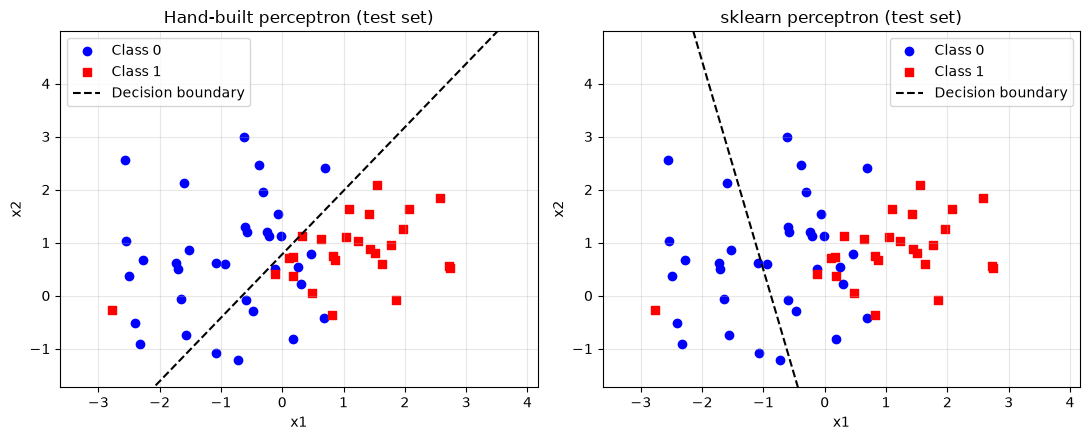

In [17]:
# Q5
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

# hand-built perceptron
w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr)
pred_h = np.array([predict(w_h, xi, b_h) for xi in Xs_te])

# sklearn perceptron
sk = Perceptron(random_state=42).fit(Xs_tr, ys_tr)
pred_s = sk.predict(Xs_te)

print(f"{'Model':<11} | {'Accuracy':>8} | {'Epochs':>6} | w, b")
print(f"{'Hand-built':<11} | {accuracy_score(ys_te, pred_h):>8.4f} | {len(m_h):>6} | {np.round(w_h,3)}, {b_h:.3f}")
print(f"{'sklearn':<11} | {accuracy_score(ys_te, pred_s):>8.4f} | {sk.n_iter_:>6} | {np.round(sk.coef_[0],3)}, {sk.intercept_[0]:.3f}")
print("Hand-built mistakes in final epoch:", m_h[-1])

xl = (Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5)
yl = (Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (w_, b_, name) in zip(axes, [(w_h, b_h, "Hand-built"), (sk.coef_[0], sk.intercept_[0], "sklearn")]):
    ax.scatter(Xs_te[ys_te == 0, 0], Xs_te[ys_te == 0, 1], c='blue', marker='o', label='Class 0')
    ax.scatter(Xs_te[ys_te == 1, 0], Xs_te[ys_te == 1, 1], c='red',  marker='s', label='Class 1')
    plot_boundary(ax, w_, b_, xlim=xl, ylim=yl)
    ax.set_title(f"{name} perceptron (test set)"); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- Accuracy: The hand-built perceptron scores 0.817 and sklearn’s scores 0.667.
- Epochs: The hand-built one runs all 100 epochs and still makes 33 mistakes in the last one, so it never converges. sklearn stops after 6 epochs because of its tolerance rule.
- Final w and b: hand-built w = [0.307, −0.256], b = 0.2; sklearn w = [2.281, 0.58], b = 2.0. The two runs end at different points of an oscillating sequence, so the weights differ a lot, and sklearn also shuffles the data each epoch.
- Plot: Both boundaries are straight lines, but they tilt in different directions.

The two clusters overlap, so the data are not perfectly linearly separable. On non-separable data the perceptron’s weights keep oscillating, so the final result depends on when training stops. Here the hand-built run happened to stop on a better weight vector. For a more stable result, we will use feature scaling or logistic regression.